In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
fileName = r"C:\Users\justi\OneDrive\Documents\GEOL_415\Assignments\Data\LA_AQS_2023.csv"
pd.read_csv(fileName)

,State Code,County Code,Site Number,Parameter Code,POC,Latitude,Longitude,Datum,Parameter Name,Duration Description,...,AQI,Daily Criteria Indicator,Tribe Name,State Name,County Name,City Name,Local Site Name,Address,MSA or CBSA Name,Data Source
0,6,37,1103,68103,1,34.06659,-118.22688,WGS84,Ambient Min Temperature,24 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
1,6,37,1103,42602,3,34.06659,-118.22688,WGS84,Nitrogen dioxide (NO2),1 HOUR,...,16,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
2,6,37,1103,62201,1,34.06659,-118.22688,WGS84,Relative Humidity,1 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
3,6,37,1103,62101,1,34.06659,-118.22688,WGS84,Outdoor Temperature,1 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
4,6,37,1103,42603,1,34.06659,-118.22688,WGS84,Oxides of nitrogen (NOx),1 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22155,6,37,1103,63301,1,34.06659,-118.22688,WGS84,Solar radiation,1 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
22156,6,37,1103,61104,1,34.06659,-118.22688,WGS84,Wind Direction - Resultant,1 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
22157,6,37,1103,61103,1,34.06659,-118.22688,WGS84,Wind Speed - Resultant,1 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
22158,6,37,1103,62201,1,34.06659,-118.22688,WGS84,Relative Humidity,1 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart


In [3]:
df = pd.read_csv(fileName)

In [4]:
df['Parameter Name']

0           Ambient Min Temperature
1            Nitrogen dioxide (NO2)
2                 Relative Humidity
3               Outdoor Temperature
4          Oxides of nitrogen (NOx)
                    ...            
22155               Solar radiation
22156    Wind Direction - Resultant
22157        Wind Speed - Resultant
22158             Relative Humidity
22159           Outdoor Temperature
Name: Parameter Name, Length: 22160, dtype: str

In [5]:
df_O3 = df[(df['Parameter Name']=='Ozone') & (df['Units of Measure']=='Parts per million')]
df_O3.head()

df_O3['Ozone_ppb'] = df_O3['Arithmetic Mean'] * 1000

In [6]:
df_O3.columns

Index(['State Code', 'County Code', 'Site Number', 'Parameter Code', 'POC',
       'Latitude', 'Longitude', 'Datum', 'Parameter Name',
       'Duration Description', 'Pollutant Standard', 'Date (Local)', 'Year',
       'Day In Year (Local)', 'Units of Measure', 'Exceptional Data Type',
       'Nonreg Observation Count', 'Observation Count', 'Observation Percent',
       'Nonreg Arithmetic Mean', 'Arithmetic Mean',
       'Nonreg First Maximum Value', 'First Maximum Value',
       'First Maximum Hour', 'AQI', 'Daily Criteria Indicator', 'Tribe Name',
       'State Name', 'County Name', 'City Name', 'Local Site Name', 'Address',
       'MSA or CBSA Name', 'Data Source', 'Ozone_ppb'],
      dtype='str')

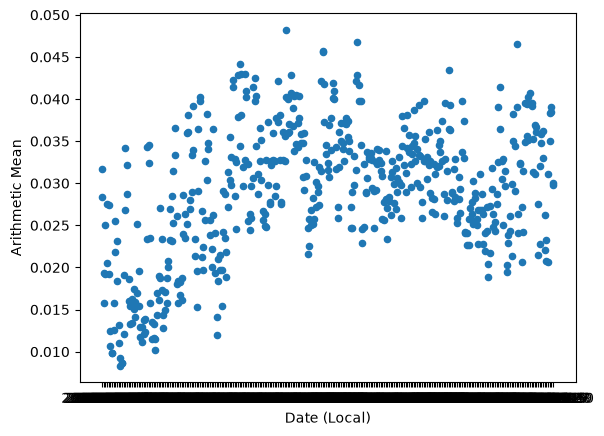

In [7]:
ax1 = df_O3.plot.scatter(x='Date (Local)',y='Arithmetic Mean') # Terrible x axis. 

In [8]:
df_O3["Date (Local)"]

20       2023-01-01
21       2023-01-01
64       2023-01-02
65       2023-01-02
204      2023-01-03
            ...    
21219    2023-09-28
21261    2023-09-29
21262    2023-09-29
21305    2023-09-30
21306    2023-09-30
Name: Date (Local), Length: 546, dtype: str

In [9]:
df_O3["Date (Local)"] = pd.to_datetime(df_O3["Date (Local)"])

In [10]:
df_O3["Date (Local)"]

20      2023-01-01
21      2023-01-01
64      2023-01-02
65      2023-01-02
204     2023-01-03
           ...    
21219   2023-09-28
21261   2023-09-29
21262   2023-09-29
21305   2023-09-30
21306   2023-09-30
Name: Date (Local), Length: 546, dtype: datetime64[us]

In [11]:
date = df_O3["Date (Local)"]
value = df_O3["Arithmetic Mean"]

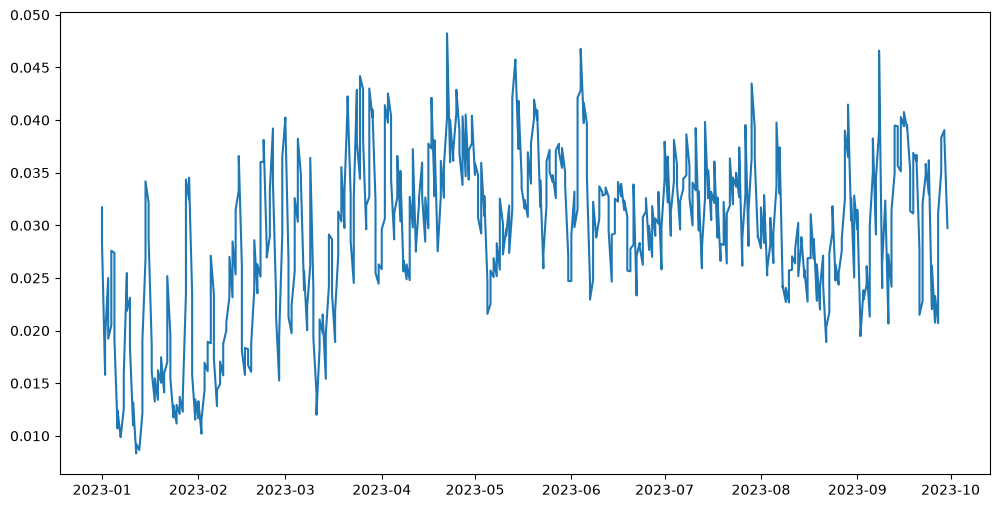

In [12]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(date, value)

In [25]:
max_idx = df_O3["Ozone_ppb"].idxmax()

highest_O3 = df_O3.loc[max_idx, "Ozone_ppb"]
highest_date = df_O3.loc[max_idx, "Date (Local)"]

print("a. Highest O3 concentration:")
print(f"Date: {highest_date}")
print(f"Concentration: {highest_O3:.2f} ppb")

a. Highest O3 concentration:
Date: 2023-04-22 00:00:00
Concentration: 48.23 ppb


In [27]:
above_35 = df_O3[df_O3["Ozone_ppb"] > 35]

num_days = above_35["Date (Local)"].dt.date.nunique()

print("\nb. Number of days with O3 above 35 ppbv:")
print(num_days)


b. Number of days with O3 above 35 ppbv:
88


In [28]:
#a. The O3 monitor shows the highest count on April 22, 2023. 
#b. Ozone concentr

In [ ]:
#Apologies, I had a change in formatting and accidentally submitted the incorrect notebook.